In [1]:
import h5py
import struct
import matplotlib.pyplot as plt

In [2]:
from acconeer.exptool.a121._core.recording import open_record
from acconeer.exptool.a121.algo.presence._detector import _load_algo_data, Detector
from acconeer.exptool.a121.algo.presence._processors import Processor

In [1]:
import acconeer.exptool.a121
print(acconeer.exptool.a121.__file__)

/opt/miniconda3/envs/acconneer/lib/python3.13/site-packages/acconeer/exptool/a121/__init__.py


In [4]:
FRAME_RATE = 10
FILE_PATH = "../tests/one-after-another-3.h5"

with open_record(FILE_PATH) as record:
    algo_group = record.get_algo_group("presence_detector")
    sensor_id, detector_config, detector_context = _load_algo_data(algo_group)

    session = record.session(0)

    # FIX: Extract correct SensorConfig from SessionConfig
    sensor_config = session.session_config.sensor_config
    metadata = session.extended_metadata[0][sensor_id]

    processor_config = Detector._get_processor_config(detector_config)

    processor = Processor(
        sensor_config=sensor_config,
        metadata=metadata,
        processor_config=processor_config,
        context=detector_context
    )


    intra_scores = []

    for frame_data in session.extended_results:
        result_dict = frame_data[0]  # assuming one group
        result = result_dict[sensor_id]  # this is already an a121.Result

        processor_result = processor.process(result)
        intra_scores.append(processor_result.intra_presence_score)


print(intra_scores)

[np.float64(0.36846476401013806), np.float64(0.6841603513422565), np.float64(0.8515538995456055), np.float64(1.0249608984416496), np.float64(1.1421792329068312), np.float64(1.1760342936865378), np.float64(1.2196966262379538), np.float64(1.2369518270191484), np.float64(1.2888534362565984), np.float64(1.292521431665936), np.float64(1.4723948368622737), np.float64(1.7944440208165748), np.float64(2.453731634948052), np.float64(3.191023955403204), np.float64(3.23594331666616), np.float64(2.968137414377919), np.float64(2.6067501202307812), np.float64(2.318474149431732), np.float64(2.0696961680595014), np.float64(1.8824206153611904), np.float64(1.7606471558530343), np.float64(1.63576613559406), np.float64(1.547716732587066), np.float64(1.4815372378521094), np.float64(1.4356553720047325), np.float64(1.3814089563598944), np.float64(1.3682878865081496), np.float64(1.3356934281718937), np.float64(1.2952656096350124), np.float64(1.2569141775515025), np.float64(1.2393264755483373), np.float64(1.226

In [ ]:
from record_bikes import load_event_data
events = load_event_data('../tests/one-after-another-3.csv')
bike_t = events['BIKE']
bike_t

[1.205598, 6.003197, 7.101011]

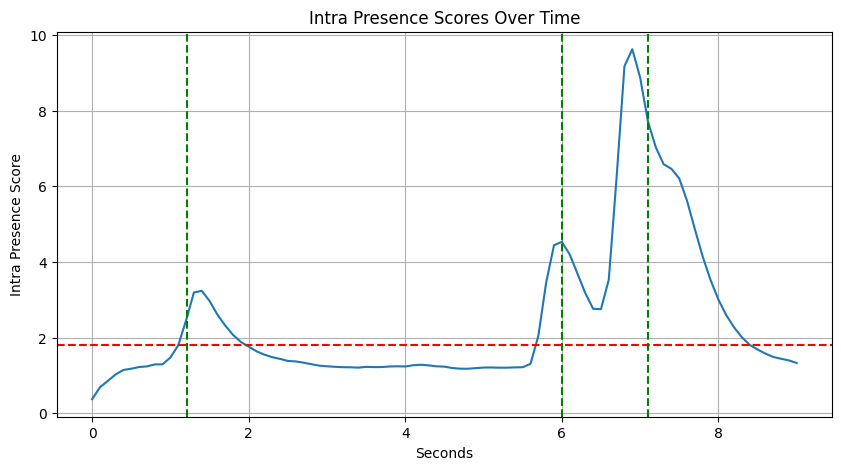

In [16]:
THRESHOLD = 1.8
# print intra_scores
plt.figure(figsize=(10, 5))
plt.plot([i / FRAME_RATE for i in range(len(intra_scores))], intra_scores)
plt.axhline(y=THRESHOLD, color='r', linestyle='--', label='Threshold')
for t in bike_t:
    plt.axvline(x=t, color='g', linestyle='--', label='Bike Event' if t == bike_t[0] else "")
plt.title('Intra Presence Scores Over Time')
plt.xlabel('Seconds')
plt.ylabel('Intra Presence Score')
plt.grid()
plt.show()

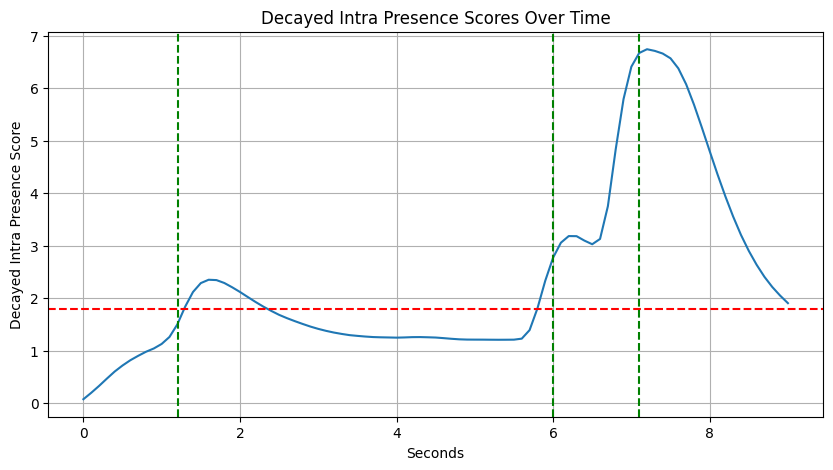

In [21]:
class ExponentialDecay:
    def __init__(self, ALPHA):
        self.ALPHA = ALPHA
        self.y = 0

    def update(self, x):
        self.y = self.ALPHA * self.y + (1 - self.ALPHA) * x
        return self.y
    
decay = ExponentialDecay(ALPHA=0.8)
decayed = [decay.update(x) for x in intra_scores]

# plot decayed scores
plt.figure(figsize=(10, 5))
plt.plot([i / FRAME_RATE for i in range(len(decayed))], decayed)
plt.axhline(y=THRESHOLD, color='r', linestyle='--', label='Threshold')
for t in bike_t:
    plt.axvline(x=t, color='g', linestyle='--', label='Bike Event' if t == bike_t[0] else "")
plt.title('Decayed Intra Presence Scores Over Time')
plt.xlabel('Seconds')
plt.ylabel('Decayed Intra Presence Score')
plt.grid()
plt.show()

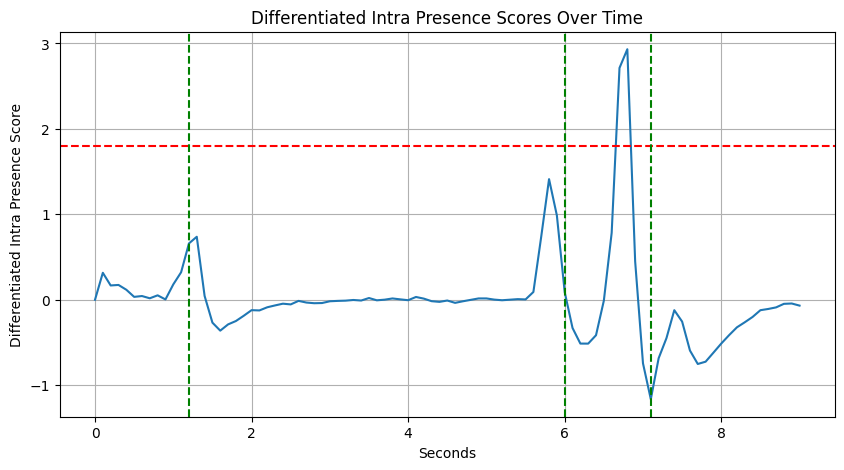

In [23]:
class Differentiator:
    def __init__(self):
        self.prev_x = None

    def update(self, x):
        if self.prev_x is None:
            self.prev_x = x
            return 0
        dy = x - self.prev_x
        self.prev_x = x
        return dy
    
diff = Differentiator()
differentiated = [diff.update(x) for x in intra_scores]

# plot differentiated scores
plt.figure(figsize=(10, 5))
plt.plot([i / FRAME_RATE for i in range(len(differentiated))], differentiated)
plt.axhline(y=THRESHOLD, color='r', linestyle='--', label='Zero Line')
for t in bike_t:
    plt.axvline(x=t, color='g', linestyle='--', label='Bike Event' if t == bike_t[0] else "")
plt.title('Differentiated Intra Presence Scores Over Time')
plt.xlabel('Seconds')
plt.ylabel('Differentiated Intra Presence Score')
plt.grid()
plt.show()

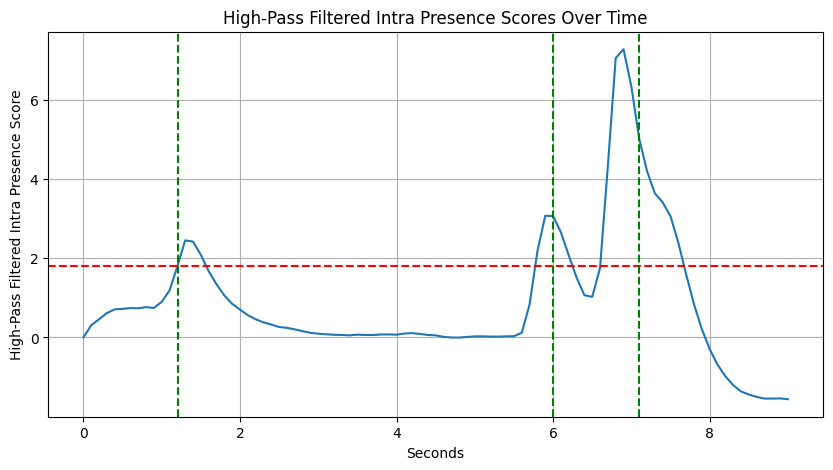

In [24]:
class HighPassFilter:
    def __init__(self, ALPHA):
        self.ALPHA = ALPHA
        self.prev_y = 0
        self.prev_x = None

    def update(self, x):
        if self.prev_x is None:
            self.prev_x = x
            return 0
        y = self.ALPHA * (self.prev_y + x - self.prev_x)
        self.prev_y = y
        self.prev_x = x
        return y


hpf = HighPassFilter(ALPHA=0.97)
high_passed = [hpf.update(x) for x in intra_scores]

# plot high-pass filtered scores
plt.figure(figsize=(10, 5))
plt.plot([i / FRAME_RATE for i in range(len(high_passed))], high_passed)
plt.axhline(y=THRESHOLD, color='r', linestyle='--', label='Zero Line')
for t in bike_t:
    plt.axvline(x=t, color='g', linestyle='--', label='Bike Event' if t == bike_t[0] else "")
plt.title('High-Pass Filtered Intra Presence Scores Over Time')
plt.xlabel('Seconds')
plt.ylabel('High-Pass Filtered Intra Presence Score')
plt.grid()

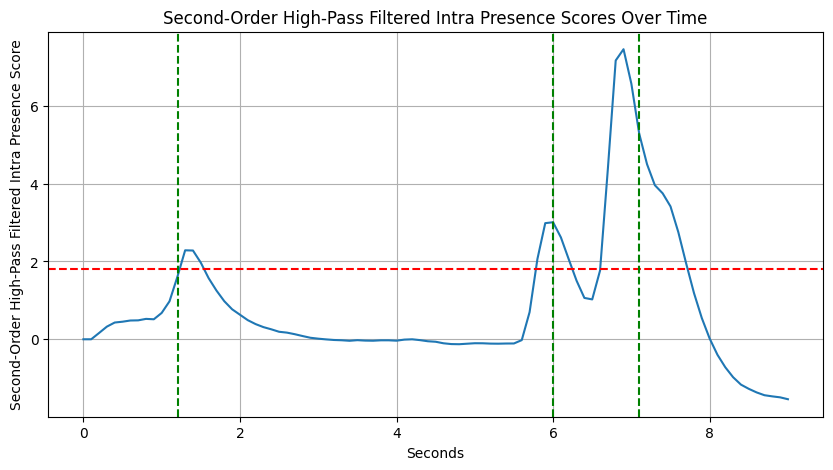

In [33]:
# second-order high-pass filter
class SecondOrderHighPassFilter:
    def __init__(self, ALPHA):
        self.alpha = ALPHA
        self.y1, self.x1 = 0, None
        self.y2, self.x2 = 0, None

    def update(self, x):
        if self.x1 is None:
            self.x1 = x
            return 0
        y1 = self.alpha * (self.y1 + x - self.x1)
        self.y1, self.x1 = y1, x

        if self.x2 is None:
            self.x2 = y1
            return 0
        y2 = self.alpha * (self.y2 + y1 - self.x2)
        self.y2, self.x2 = y2, y1
        return y2

second_order_hpf = SecondOrderHighPassFilter(ALPHA=0.99)
second_order_high_passed = [second_order_hpf.update(x) for x in intra_scores]

# plot second-order high-pass filtered scores
plt.figure(figsize=(10, 5))
plt.plot([i / FRAME_RATE for i in range(len(second_order_high_passed))], second_order_high_passed)
plt.axhline(y=THRESHOLD, color='r', linestyle='--', label='Zero Line')
for t in bike_t:
    plt.axvline(x=t, color='g', linestyle='--', label='Bike Event' if t == bike_t[0] else "")
plt.title('Second-Order High-Pass Filtered Intra Presence Scores Over Time')
plt.xlabel('Seconds')
plt.ylabel('Second-Order High-Pass Filtered Intra Presence Score')
plt.grid()

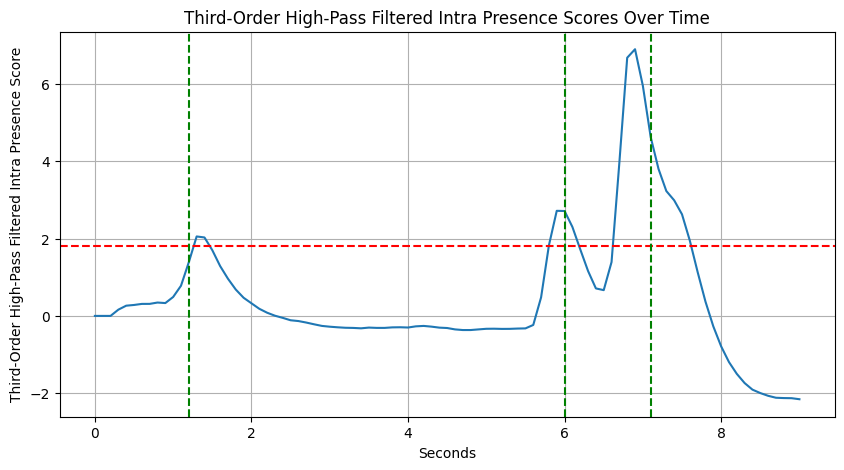

In [30]:
class ThirdOrderHighPassFilter:
    def __init__(self, alpha):
        self.alpha = alpha
        self.y1, self.x1 = 0, None
        self.y2, self.x2 = 0, None
        self.y3, self.x3 = 0, None

    def update(self, x):
        if self.x1 is None:
            self.x1 = x
            return 0
        y1 = self.alpha * (self.y1 + x - self.x1)
        self.y1, self.x1 = y1, x

        if self.x2 is None:
            self.x2 = y1
            return 0
        y2 = self.alpha * (self.y2 + y1 - self.x2)
        self.y2, self.x2 = y2, y1

        if self.x3 is None:
            self.x3 = y2
            return 0
        y3 = self.alpha * (self.y3 + y2 - self.x3)
        self.y3, self.x3 = y3, y2
        return y3

third_order_hpf = ThirdOrderHighPassFilter(alpha=0.99)
third_order_high_passed = [third_order_hpf.update(x) for x in intra_scores]

# plot third-order high-pass filtered scores
plt.figure(figsize=(10, 5))
plt.plot([i / FRAME_RATE for i in range(len(third_order_high_passed))], third_order_high_passed)
plt.axhline(y=THRESHOLD, color='r', linestyle='--', label='Zero Line')
for t in bike_t:
    plt.axvline(x=t, color='g', linestyle='--', label='Bike Event' if t == bike_t[0] else "")
plt.title('Third-Order High-Pass Filtered Intra Presence Scores Over Time')
plt.xlabel('Seconds')
plt.ylabel('Third-Order High-Pass Filtered Intra Presence Score')
plt.grid()

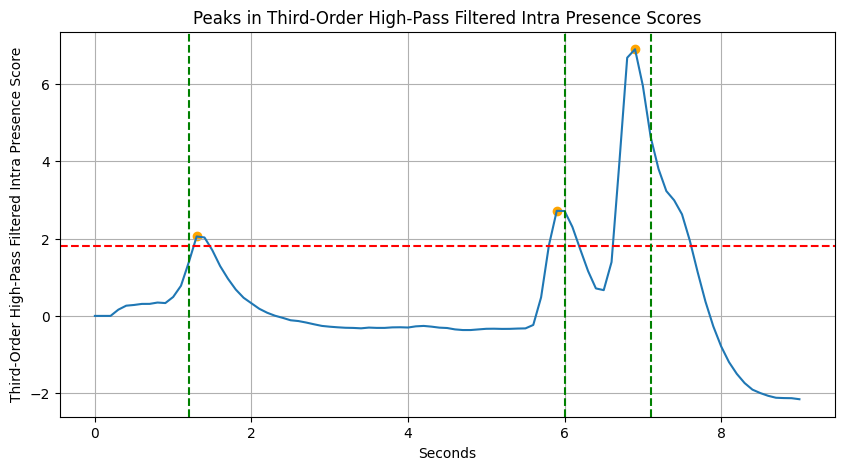

In [34]:
# find peaks
from scipy.signal import find_peaks
peaks, _ = find_peaks(third_order_high_passed, height=0.5)
plt.figure(figsize=(10, 5))
plt.plot([i / FRAME_RATE for i in range(len(third_order_high_passed))], third_order_high_passed)
plt.axhline(y=THRESHOLD, color='r', linestyle='--', label='Zero Line')
for t in bike_t:
    plt.axvline(x=t, color='g', linestyle='--', label='Bike Event' if t == bike_t[0] else "")
plt.scatter([p / FRAME_RATE for p in peaks], [third_order_high_passed[p] for p in peaks], color='orange', label='Peaks')
plt.title('Peaks in Third-Order High-Pass Filtered Intra Presence Scores')
plt.xlabel('Seconds')
plt.ylabel('Third-Order High-Pass Filtered Intra Presence Score')
plt.grid()

In [ ]:
np.tan()